# 05 — Açıklanabilir Yapay Zekâ (XAI): SHAP Analizi

**Proje:** NASA C-MAPSS FD001 — Motorların kalan kullanım ömrü (RUL) tahmini  
**Açıklanan model:** Validation RMSE değerine göre seçilen XGBoost regresyon modeli.

Bu çalışmada, model geliştirme aşamasında belirlenen hiperparametreler kullanılarak XGBoost modeli yeniden eğitilmiştir. Ardından modelin tahminlerini açıklamak amacıyla SHAP yöntemi uygulanmıştır.

Test verileri model eğitimi ve hiperparametre seçiminde kullanılmamış, yalnızca performans değerlendirmesi ve açıklanabilirlik analizinde kullanılmıştır.

**Gerekli dosyalar:** `artifacts/train_fe.csv`, `artifacts/val_fe.csv`, `artifacts/test_fe.csv`, `artifacts/selected_features.json` ve `data/RUL_FD001.txt`.

## 5.1 XAI yöntemlerinin araştırılması ve seçimi

| Yöntem | Güçlü tarafı | Bu proje için sınırlaması |
|---|---|---|
| Permutation Importance | Karıştırılan özelliğin tahmin hatasını ne kadar değiştirdiğini ölçer | İlişkili sensörlerde önem dağılımı yanıltıcı olabilir |
| PDP (Partial Dependence Plot) | Özellik ile ortalama model yanıtı ilişkisini görselleştirir | İlişkili özelliklerde gerçekçi olmayan birleşimler üretebilir |
| LIME | Bir tekil tahminin çevresinde basit bir açıklama kurar | Açıklama örneklemeye ve yerel yaklaşım ayarlarına duyarlı olabilir |
| **SHAP** | Özelliklerin tahmine katkısını hem tekil hem toplu düzeyde gösterir | Özellik bağımlılıkları ve arka plan dağılımı yorumu etkiler; nedensellik göstermez |

**Seçim:** Ağaç tabanlı XGBoost'u açıklamak, genel özellik etkilerini ve tek bir motor tahminini göstermek için **SHAP TreeExplainer** kullanıyoruz. TreeExplainer Random Forest ile de kullanılabilir. XGBoost burada 04 bölümündeki validation-temelli seçilen model olduğu için incelenmektedir.

## 5.2 Kütüphaneler ve veri hazırlığı



In [12]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

RUL_CAP = 125.0
TARGET_COL = "RUL_capped125"

base_dir = Path.cwd()
project_root = (
    base_dir.parent
    if base_dir.name == "notebooks" and (base_dir.parent / "artifacts").exists()
    else base_dir
)
artifacts_dir = project_root / "artifacts"
data_candidates = [project_root / "data", Path("data"), Path("../data")]
data_dir = next((p for p in data_candidates if (p / "RUL_FD001.txt").exists()), None)

for filename in ["train_fe.csv", "val_fe.csv", "test_fe.csv", "selected_features.json"]:
    assert (artifacts_dir / filename).exists(), f"Eksik dosya: {artifacts_dir / filename}"
assert data_dir is not None, "RUL_FD001.txt bulunamadı. data/ klasörünü kontrol edin."

train_fe = pd.read_csv(artifacts_dir / "train_fe.csv")
val_fe = pd.read_csv(artifacts_dir / "val_fe.csv")
test_fe = pd.read_csv(artifacts_dir / "test_fe.csv")
with open(artifacts_dir / "selected_features.json", encoding="utf-8") as f:
    selected_features = json.load(f)["selected_features"]

val_units = set(val_fe["unit"].unique())
train_only_df = train_fe[~train_fe["unit"].isin(val_units)].copy()
assert set(train_only_df["unit"]).isdisjoint(val_units)
X_tr = train_only_df[selected_features]
y_tr = train_only_df[TARGET_COL]
X_val = val_fe[selected_features]
y_val = val_fe[TARGET_COL]

test_last = test_fe.sort_values("cycle").groupby("unit", as_index=False).last()
X_test_last = test_last[selected_features]
y_true_raw = pd.read_csv(
    data_dir / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"]
)["RUL"].to_numpy()
y_test_true = np.minimum(y_true_raw, RUL_CAP)
assert len(X_test_last) == len(y_test_true), "Test motor sayısı ve gerçek RUL sayısı uyuşmuyor."
print(f"Eğitim satırları: {len(X_tr)}, validation: {len(X_val)}, test motoru: {len(X_test_last)}")
print(f"Özellik sayısı: {len(selected_features)}")

Eğitim satırları: 16561, validation: 4070, test motoru: 100
Özellik sayısı: 51


## 5.3 Açıklanacak XGBoost modelini oluşturma

Validation RMSE'ye göre seçilmiş ayarlar: **200 ağaç, maksimum derinlik 4, öğrenme hızı 0.05**. SHAP analizi için test verisi üzerinde model ayarlaması yapılmaz. Önce test RMSE'nin önceki çalışmayla uyumlu olup olmadığı kontrol edilir.

In [4]:
selected_xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)
selected_xgb_model.fit(X_tr, y_tr)
xgb_test_pred = selected_xgb_model.predict(X_test_last)
val_rmse = np.sqrt(mean_squared_error(y_val, selected_xgb_model.predict(X_val)))
test_rmse = np.sqrt(mean_squared_error(y_test_true, xgb_test_pred))
print(f"Validation RMSE: {val_rmse:.2f} | Test RMSE: {test_rmse:.2f}")
print("04 notebook'undaki yaklaşık 16.16 / 18.25 değerleriyle karşılaştırın.")

Validation RMSE: 16.16 | Test RMSE: 18.25
04 notebook'undaki yaklaşık 16.16 / 18.25 değerleriyle karşılaştırın.


## 5.4 SHAP değerlerini hesaplama

SHAP değeri pozitifse özellik **tahmin edilen RUL'ü artırır**, negatifse **azaltır**. Bu, özelliğin fiziksel olarak arızaya neden olduğu anlamına gelmez. Buradaki hesaplamalar **test motorlarının son döngülerindeki** tahminleri açıklar.

In [5]:
explainer = shap.TreeExplainer(selected_xgb_model)
shap_values = explainer(X_test_last)
print("SHAP açıklaması hazır:", shap_values.values.shape)
# Toplam katkı + temel değer, model tahminini yaklaşık olarak vermelidir.
shap_total = shap_values.base_values + shap_values.values.sum(axis=1)
print("En büyük SHAP toplama farkı:", np.max(np.abs(shap_total - xgb_test_pred)))

SHAP açıklaması hazır: (100, 51)
En büyük SHAP toplama farkı: 6.1035156e-05


## 5.5 Global SHAP — Bar Plot

Bu grafik, 100 test motoru üzerinde mutlak SHAP katkılarının ortalamasına göre özellikleri sıralar. **Yön göstermez**; önem sıralaması gösterir.

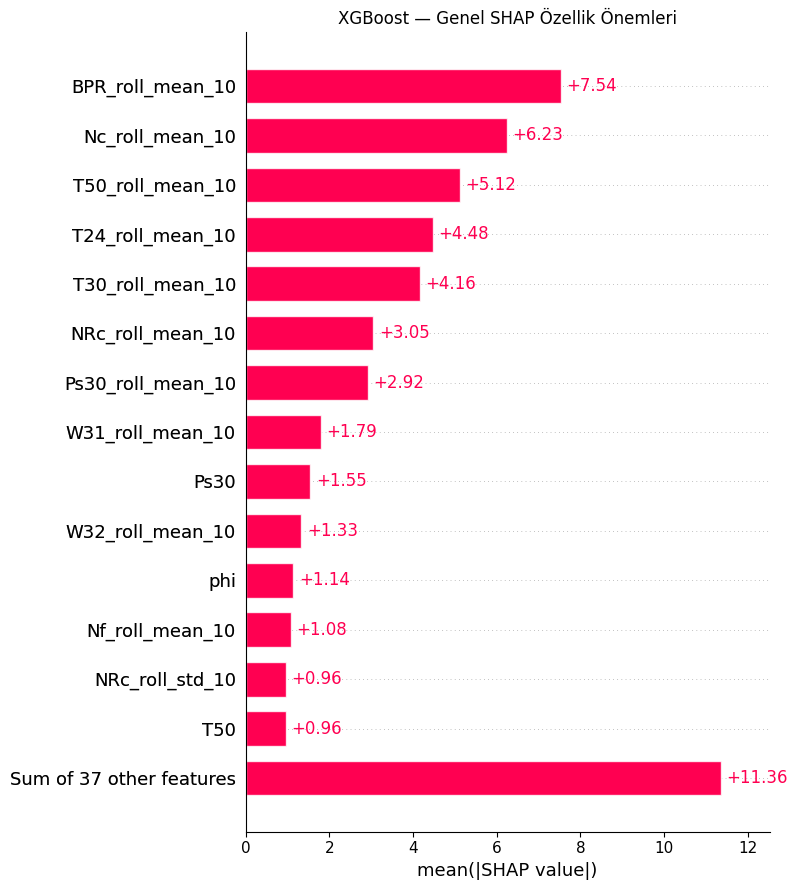

In [6]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("XGBoost — Genel SHAP Özellik Önemleri")
plt.tight_layout()
plt.show()

## 5.6 Global SHAP — Beeswarm Plot

Her nokta bir motoru temsil eder. Yatay eksendeki SHAP değeri RUL tahminini artırma/azaltma yönünü gösterir. Renkler genellikle **özellik değerinin düşük (mavi) veya yüksek (kırmızı)** olduğunu belirtir; renk doğrudan arıza riskini göstermez.

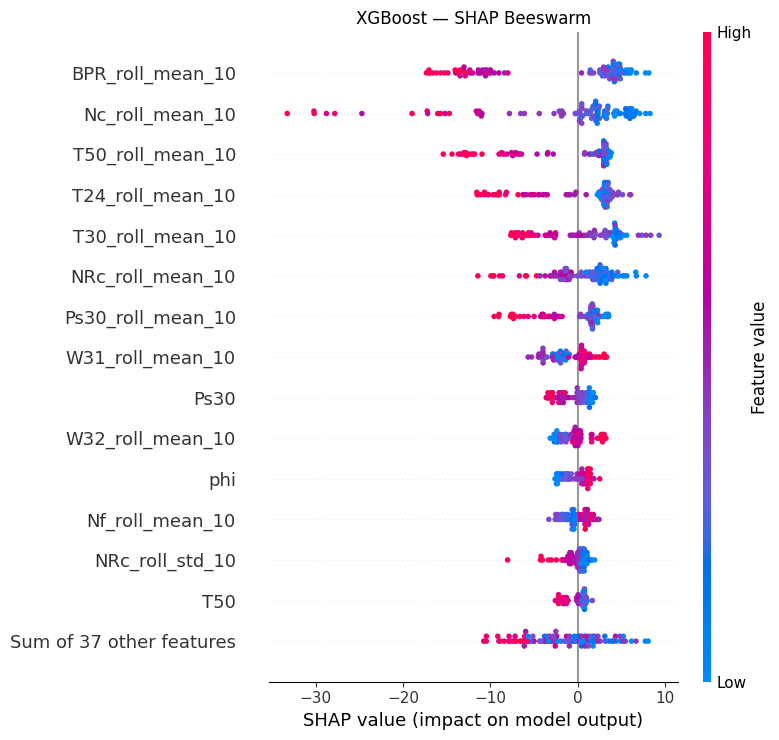

In [7]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("XGBoost — SHAP Beeswarm")
plt.tight_layout()
plt.show()

SHAP Beeswarm Plot analizinde, BPR_roll_mean_10 ve Nc_roll_mean_10 özelliklerinin RUL tahminlerinde önemli rol oynadığı görülmüştür. Bu özelliklerin yüksek değerleri çoğunlukla negatif SHAP değerlerine sahiptir. Bu durum, yüksek özellik değerlerinin modelin tahmin ettiği kalan kullanım ömrünü azaltma eğiliminde olduğunu göstermektedir.

## 5.7 Local SHAP — Waterfall Plot

### Yerel SHAP Analizi için Motor Seçimi

Yerel SHAP analizinde, test veri setindeki mutlak tahmin hatası en yüksek olan motor seçilmiştir. Bu motor üzerinde SHAP Waterfall Plot kullanılarak XGBoost modelinin tahminine hangi özelliklerin ne yönde katkı sağladığı incelenmiştir.

Bu analiz, modelin tek bir motor için verdiği tahminin nasıl oluştuğunu anlamayı amaçlamaktadır. SHAP değerleri modelin tahmin sürecini açıklamakta, ancak tahmin hatasının fiziksel nedenini doğrudan ortaya koymamaktadır.

İncelenen test motoru: 27
Gerçek RUL: 66.00
Tahmin edilen RUL: 118.98
Mutlak hata: 52.98


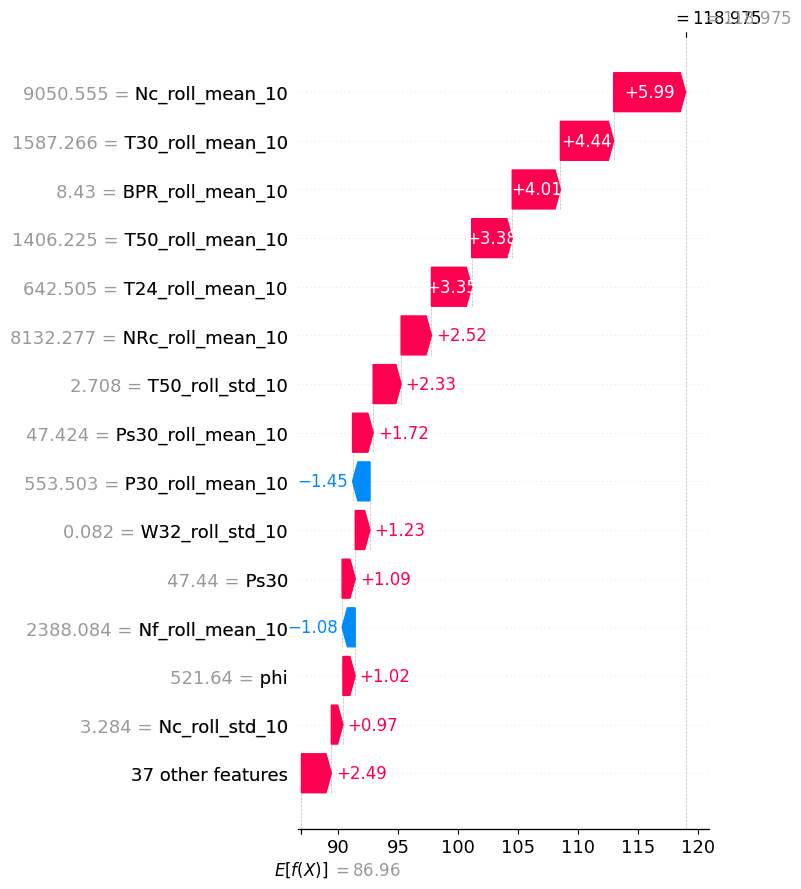

In [9]:
abs_error = np.abs(y_test_true - xgb_test_pred)
row_idx = int(np.argmax(abs_error))
unit_id = int(test_last.iloc[row_idx]["unit"])
print(f"İncelenen test motoru: {unit_id}")
print(f"Gerçek RUL: {y_test_true[row_idx]:.2f}")
print(f"Tahmin edilen RUL: {xgb_test_pred[row_idx]:.2f}")
print(f"Mutlak hata: {abs_error[row_idx]:.2f}")
shap.plots.waterfall(shap_values[row_idx], max_display=15, show=False)
plt.tight_layout()
plt.show()

### SHAP Waterfall Plot Sonuçlarının Değerlendirilmesi

SHAP Waterfall Plot kullanılarak test veri setinden seçilen bir motorun RUL tahmini incelenmiştir.

Modelin yaklaşık 86.96 döngülük referans tahmininden başlayarak, ilgili motorun özellikleri doğrultusunda yaklaşık 119 döngülük RUL tahminine ulaştığı görülmüştür.

Tahmini artıran en önemli özellikler `Nc_roll_mean_10` (+5.99), `T30_roll_mean_10` (+4.44) ve `BPR_roll_mean_10` (+4.01) olmuştur. Buna karşılık `P30_roll_mean_10` özelliği tahmini yaklaşık 1.45 döngü azaltmıştır.

Bu analiz, modelin belirli bir motor için verdiği tahminin hangi özellik katkılarından oluştuğunu göstermektedir. SHAP değerleri modelin karar mekanizmasını açıklamakta, ancak sensörler ile fiziksel arıza arasında doğrudan nedensellik kanıtı sunmamaktadır.

In [11]:
print("Motor numarası:", unit_id)
print("Gerçek RUL:", y_test_true[row_idx])
print("Tahmin edilen RUL:", round(float(xgb_test_pred[row_idx]), 2))
print("Mutlak hata:", round(float(abs_error[row_idx]), 2))

Motor numarası: 27
Gerçek RUL: 66.0
Tahmin edilen RUL: 118.98
Mutlak hata: 52.98


### Yerel SHAP Analizi ve Tahmin Hatasının Değerlendirilmesi

Yerel açıklanabilirlik analizinde test veri setindeki 27 numaralı motor incelenmiştir. Motorun gerçek kalan kullanım ömrü 66 döngü olmasına rağmen, XGBoost modeli 118.98 döngü tahmin etmiştir. Böylece 52.98 döngülük mutlak tahmin hatası oluşmuştur.

SHAP Waterfall Plot sonucunda `Nc_roll_mean_10`, `T30_roll_mean_10` ve `BPR_roll_mean_10` özelliklerinin tahmin edilen RUL değerini artıran başlıca değişkenler olduğu görülmüştür.

Bu sonuç, modelin ilgili motorun kalan kullanım ömrünü olduğundan yüksek tahmin ettiğini ve bazı sensör özelliklerinin bu yüksek tahmine pozitif katkı sağladığını göstermektedir.

SHAP analizi modelin tahminini açıklamakta, ancak gerçek kalan ömür ile tahmin arasındaki farkın fiziksel nedenini tek başına belirlememektedir.

### 5.8 Genel Sonuç ve Değerlendirme

Bu çalışmada, NASA C-MAPSS FD001 veri seti üzerinde eğitilen XGBoost modelinin tahminlerini açıklamak amacıyla SHAP yöntemi kullanılmıştır. Analizler, 100 test motorunun son gözlem döngüleri üzerinden gerçekleştirilmiştir.

**Global SHAP analizi** sonucunda `BPR_roll_mean_10`, `Nc_roll_mean_10` ve `T50_roll_mean_10` özelliklerinin modelin RUL tahminlerinde en etkili değişkenler arasında olduğu belirlenmiştir. Beeswarm grafiğinde bu özelliklerin yüksek değerlerinin çoğunlukla RUL tahminini azaltma yönünde katkı sağladığı görülmüştür.

**Local SHAP analizi** kapsamında 27 numaralı motor incelenmiştir. Motorun gerçek RUL değeri 66 döngü olmasına rağmen model 118.98 döngü tahmin etmiş ve 52.98 döngülük mutlak hata oluşmuştur. Waterfall grafiği, bu tahminin oluşmasında özellikle `Nc_roll_mean_10`, `T30_roll_mean_10` ve `BPR_roll_mean_10` özelliklerinin pozitif katkı sağladığını göstermiştir.

Sonuç olarak SHAP yöntemi, XGBoost modelinin hangi özelliklere dayalı tahminler oluşturduğunu hem genel hem de tekil motor düzeyinde açıklamamızı sağlamıştır. Bununla birlikte SHAP değerleri, sensörler ile motor arızası arasındaki fiziksel neden-sonuç ilişkilerini tek başına kanıtlamamaktadır.

Bu analiz, kestirimci bakım uygulamalarında model tahminlerinin daha anlaşılır ve incelenebilir hâle getirilmesine katkı sağlamaktadır.